# UFC Fight Predictor — Informe reproducible del proyecto

Este notebook resume de forma ejecutable todo el proyecto: las fuentes de datos, la
ingeniería de variables, el entrenamiento y evaluación de los modelos, y un ejemplo
real de predicción (Tom Nolan vs. Renato Moicano) generado con el mismo pipeline que
usa la aplicación web.

> **Aviso:** las predicciones son estimaciones experimentales sobre datos históricos.
> No garantizan resultados ni constituyen consejo de apuestas.

## 1. Objetivo

Responder dos preguntas de clasificación sobre peleas de UFC:

1. **¿Qué esquina ganará?** — modelo binario (esquina roja vs. azul).
2. **¿Cómo terminará?** — modelo de seis clases que combina esquina y método
   (KO/TKO, sumisión o decisión).

La evaluación se hace de forma **cronológica**: entrenar con peleas antiguas y probar
con las más recientes, evitando la fuga de información.

## 2. Datos

In [1]:
from pathlib import Path
import warnings
import pandas as pd

warnings.filterwarnings("ignore")

_cwd = Path.cwd()
PROJECT_DIR = _cwd if (_cwd / "app.py").exists() else _cwd.parent
if not (PROJECT_DIR / "app.py").exists():
    raise FileNotFoundError("Ejecuta el notebook desde la carpeta ufc-predictor")
PROCESSED = PROJECT_DIR / "data" / "processed" / "ufc_features_con_cuotas.csv"
REPORTS = PROJECT_DIR / "reports"

features = pd.read_csv(PROCESSED, low_memory=False)
print("Filas (peleas):", len(features))
print("Columnas:", len(features.columns))
features[["event_date", "R_fighter", "B_fighter", "weight_class", "R_odds", "B_odds"]].head()

Filas (peleas): 7167
Columnas: 114


,event_date,R_fighter,B_fighter,weight_class,R_odds,B_odds
0,2026-03-28,Israel Adesanya,Joe Pyfer,Middleweight,-130.0,102.0
1,2026-03-28,Alexa Grasso,Maycee Barber,Women's Flyweight,124.0,-158.0
2,2026-03-28,Michael Chiesa,Niko Price,Welterweight,-901.0,550.0
3,2026-03-28,Julian Erosa,Lerryan Douglas,Featherweight,235.0,-320.0
4,2026-03-28,Mansur Abdul-Malik,Yousri Belgaroui,Middleweight,-158.0,124.0


In [2]:
features["weight_class"].value_counts().head(10)

weight_class
Lightweight            1159
Welterweight           1097
Middleweight            871
Featherweight           833
Bantamweight            752
Light Heavyweight       548
Heavyweight             539
Flyweight               404
Women's Strawweight     358
Women's Flyweight       268
Name: count, dtype: int64

## 3. Variables predictivas

Cada esquina aporta su perfil histórico más reciente (estadísticas acumuladas antes
de la pelea) y el pipeline calcula **diferencias** entre ambos peleadores, además de
variables del evento: división, título, ubicación, país, número de asaltos, género y
cuotas americanas.

In [3]:
# Cargar la lista de variables que usan los modelos entrenados
import joblib
winner_bundle = joblib.load(PROJECT_DIR / "models" / "random_forest_ufc_odds.joblib")
feature_columns = winner_bundle["feature_columns"]
print("Número de variables del modelo:", len(feature_columns))
print("\nEjemplos de variables de diferencia:")
print([c for c in feature_columns if c.endswith("_dif")][:10])

Número de variables del modelo: 109

Ejemplos de variables de diferencia:
['lose_streak_dif', 'win_streak_dif', 'longest_win_streak_dif', 'win_dif', 'loss_dif', 'total_round_dif', 'total_title_bout_dif', 'ko_dif', 'sub_dif', 'height_dif']


## 4. Evaluación de los modelos

Las métricas se leen de los reportes generados durante el entrenamiento.

In [4]:
metrics = pd.read_csv(REPORTS / "metricas_modelos_con_cuotas.csv")
metrics

,model,accuracy,balanced_accuracy,n_test
0,Regresión logística + cuotas,0.665777,0.644499,1499
1,Random Forest + cuotas,0.691127,0.671937,1499
2,XGBoost + cuotas,0.676451,0.657531,1499
3,Random Forest sin cuotas,0.635090,0.599807,1499
4,Baseline: clase más frecuente,0.558372,0.500000,1499
5,Favorito del mercado,0.695686,0.688837,1275
6,Modelo anterior (mismas peleas),0.620389,0.599282,1491


In [5]:
preds = pd.read_csv(REPORTS / "predicciones_prueba_con_cuotas.csv")
print(preds.columns.tolist())
preds.head()

['event_date', 'R_fighter', 'B_fighter', 'Winner', 'target_red', 'predicted_red', 'probability_red', 'probability_blue']


,event_date,R_fighter,B_fighter,Winner,target_red,predicted_red,probability_red,probability_blue
0,2026-03-28,Israel Adesanya,Joe Pyfer,Blue,0,1,0.550519,0.449481
1,2026-03-28,Alexa Grasso,Maycee Barber,Red,1,0,0.455237,0.544763
2,2026-03-28,Michael Chiesa,Niko Price,Red,1,1,0.796543,0.203457
3,2026-03-28,Julian Erosa,Lerryan Douglas,Blue,0,0,0.404446,0.595554
4,2026-03-28,Mansur Abdul-Malik,Yousri Belgaroui,Blue,0,1,0.576680,0.423320


In [6]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score

accuracy_rf = accuracy_score(preds["target_red"], preds["predicted_red"])
bacc_rf = balanced_accuracy_score(preds["target_red"], preds["predicted_red"])
print(f"Random Forest con cuotas — accuracy: {accuracy_rf:.1%}")
print(f"Random Forest con cuotas — balanced accuracy: {bacc_rf:.1%}")
print(f"Peleas de prueba: {len(preds)}")

Random Forest con cuotas — accuracy: 69.1%
Random Forest con cuotas — balanced accuracy: 67.2%
Peleas de prueba: 1499


## 5. Importancia de variables

Qué tanto contribuye cada variable al modelo de ganador.

In [7]:
import matplotlib.pyplot as plt

importance_path = REPORTS / "importancia_variables_con_cuotas.csv"
imp = pd.read_csv(importance_path)
print(imp.columns.tolist())
imp.head()

['feature', 'importance']


,feature,importance
0,numeric__B_odds,0.061434
1,numeric__B_ev,0.055849
2,numeric__R_odds,0.055804
3,numeric__R_ev,0.054889
4,numeric__b_dec_odds,0.030182


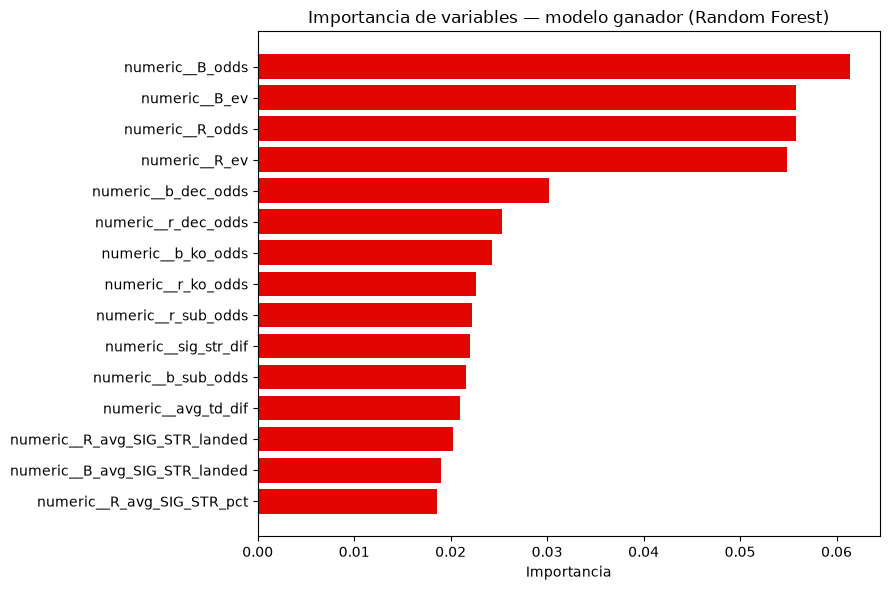

In [8]:
# Top 15 variables más importantes
col_name, val_col = "feature", "importance"
top = imp.nlargest(15, val_col)
plt.figure(figsize=(9, 6))
plt.barh(top[col_name][::-1], top[val_col][::-1], color="#e10600")
plt.title("Importancia de variables — modelo ganador (Random Forest)")
plt.xlabel("Importancia")
plt.tight_layout()
plt.show()

## 6. Ejemplo práctico: Tom Nolan vs. Renato Moicano

Reproducimos la pelea estelar de UFC Fight Night del 31 de octubre de 2026
(Meta Apex, Las Vegas, peso ligero, sin título) usando **exactamente las mismas
funciones que usa la aplicación web** (`app.py`):

- Cuotas ingresadas: **-111** (Nolan) y **-115** (Moicano), formato americano.
- Perfiles: última aparición de cada atleta en el dataset histórico.

In [9]:
import sys
sys.path.insert(0, str(PROJECT_DIR))
import app  # en modo "bare" Streamlit solo emite warnings, no bloquea

red_profile = app.load_fighter_profiles().loc[app.normalize_fighter("Tom Nolan")]
blue_profile = app.load_fighter_profiles().loc[app.normalize_fighter("Renato Moicano")]

X = app.build_matchup_features(
    red_profile,
    blue_profile,
    app.feature_columns,
    weight_class="Lightweight",
    title_bout=False,
    location="Las Vegas, Nevada",
    country="USA",
    red_odds=-111.0,
    blue_odds=-115.0,
)

# Modelo de ganador
win_probs = app.winner_model.predict_proba(X[app.feature_columns])[0]
win_classes = list(app.winner_model.steps[-1][1].classes_)
red_win = float(win_probs[win_classes.index(1)])
print(f"Tom Nolan (rojo):  {red_win:.1%}")
print(f"Renato Moicano (azul): {1 - red_win:.1%}")

2026-11-06 14:17:40.811 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


2026-11-06 14:17:40.813 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


2026-11-06 14:17:41.265 
  command:

    streamlit run C:\Users\kenne\AppData\Roaming\Python\Python311\site-packages\ipykernel_launcher.py [ARGUMENTS]


2026-11-06 14:17:41.267 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


2026-11-06 14:17:41.269 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


2026-11-06 14:17:41.272 No runtime found, using MemoryCacheStorageManager


... (81 outputs left out)

2026-11-06 14:17:41.789 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


2026-11-06 14:17:41.790 No runtime found, using MemoryCacheStorageManager


2026-11-06 14:17:41.791 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Tom Nolan (rojo):  56.8%
Renato Moicano (azul): 43.2%


In [10]:
# Modelo de esquina + método de victoria
method_probs = app.method_model.predict_proba(X[app.feature_columns])[0]
method_classes = list(app.method_model.steps[-1][1].classes_)
method_df = pd.DataFrame({
    "Resultado": method_classes,
    "Probabilidad": method_probs,
}).sort_values("Probabilidad", ascending=False)
method_df["Probabilidad"] = method_df["Probabilidad"].map(lambda v: f"{v:.1%}")
method_df

,Resultado,Probabilidad
0,Esquina azul — Decisión,22.3%
1,Esquina azul — KO/TKO,17.7%
3,Esquina roja — Decisión,15.9%
4,Esquina roja — KO/TKO,15.7%
2,Esquina azul — Sumisión,15.0%
5,Esquina roja — Sumisión,13.4%


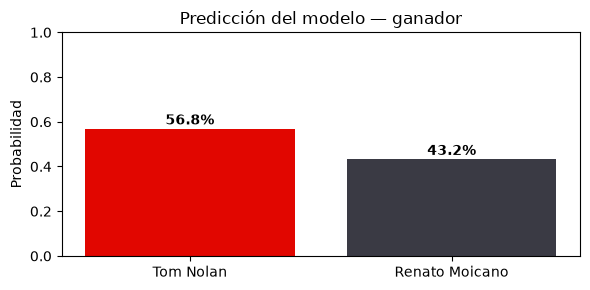

In [11]:
# Gráfica de probabilidades de ganador
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["Tom Nolan", "Renato Moicano"], [red_win, 1 - red_win], color=["#e10600", "#3a3a44"])
ax.set_ylim(0, 1)
ax.set_ylabel("Probabilidad")
ax.set_title("Predicción del modelo — ganador")
for i, v in enumerate([red_win, 1 - red_win]):
    ax.text(i, v + 0.02, f"{v:.1%}", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

## 7. La aplicación web

La misma predicción está disponible de forma interactiva en `app.py` (Streamlit):

- **Próximas peleas:** consulta la API de UFCalendar y muestra eventos, divisiones,
  récords, horarios por sección en hora de Colombia y cuotas de consenso.
- **Pelea personalizada:** asistente para elegir dos atletas, división, título,
  ubicación y cuotas; devuelve las mismas probabilidades de este notebook.

Para ejecutarla:

```bash
python -m streamlit run app.py
```

## 8. Limitaciones

- Los datos con cuotas llegan hasta el **28 de marzo de 2026**; el modelo no conoce
  peleas ni cambios posteriores.
- Los perfiles personalizados usan la última aparición histórica del atleta y pueden
  estar desactualizados (lesiones, rachas reales, etc.).
- Las cuotas faltantes se imputan con valores típicos del entrenamiento; omitirlas
  no equivale al modelo sin cuotas.
- Las probabilidades **no están calibradas** y el modelo de método tiene menor
  precisión (36,7 % de accuracy en seis clases).
- Todo lo anterior implica que las salidas son estimaciones educativas, no predicciones
  garantizadas.